## Pronóstico de series de tiempo con modelos ARIMA y SARIMA

Integrantes:

Daniela Robles Estrada, A01659074

Gerardo Javier López García, A01660262

Karen Paula Mayorga Guerrero, A01336489

Guillermo Abraham Márquez Pulido, A01666930

Jesús Jionary Gutiérrez Moreno, A01664857

Materia: Advanced Artificial Intelligence for Data Science II, Tecnológico de Monterrey, Campus Ciudad de México

Fecha: 4 de noviembre de 2026

## 1. Introducción y objetivos

Este notebook analiza el dataset Energy Consumption Prediction de Kaggle. Contiene 1,000 observaciones por hora del consumo de energía de un edificio, desde el 1 de enero de 2022 a las 00:00 hasta el 11 de febrero de 2022 a las 15:00, junto con variables de clima, ocupación y uso de equipos. La serie objetivo de esta tarea es EnergyConsumption.

Los objetivos son los siguientes. Primero, cargar y preparar la serie con un índice DateTime por hora, graficarla y describir su tendencia y estacionalidad. Segundo, evaluar la estacionariedad con las pruebas ADF y KPSS y diferenciar solo si hace falta. Tercero, usar la ACF y la PACF para proponer los órdenes del modelo, ajustar al menos dos modelos ARIMA y un SARIMA, y compararlos con AIC, BIC y RMSE. Cuarto, validar cada modelo con un diagnóstico de residuos. Por último, pronosticar las siguientes 30 horas y discutir qué modelo funciona mejor y por qué.

Para medir la precisión del pronóstico, las últimas 30 horas se separan como conjunto de prueba. Todos los modelos se entrenan con las primeras 970 horas y se evalúan en esas 30 horas. Después de elegir el mejor modelo, se vuelve a ajustar con la serie completa para pronosticar las 30 horas posteriores al final de los datos.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")  # oculta avisos de convergencia y de la tabla de valores p de statsmodels
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

## 2. Carga y preprocesamiento de datos

La columna Timestamp se convierte a fecha y hora y se usa como índice. Después se le asigna al índice una frecuencia explícita por hora, que es lo que esperan ARIMA y SARIMA.

In [2]:
df = pd.read_csv("Energy_consumption.csv", parse_dates=["Timestamp"])
df = df.set_index("Timestamp").sort_index()
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (1000, 10)


,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
Timestamp,,,,,,,,,,
2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373
2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855
2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888
2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850
2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732


In [3]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1000 entries, 2022-01-01 00:00:00 to 2022-02-11 15:00:00
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Temperature        1000 non-null   float64
 1   Humidity           1000 non-null   float64
 2   SquareFootage      1000 non-null   float64
 3   Occupancy          1000 non-null   int64  
 4   HVACUsage          1000 non-null   str    
 5   LightingUsage      1000 non-null   str    
 6   RenewableEnergy    1000 non-null   float64
 7   DayOfWeek          1000 non-null   str    
 8   Holiday            1000 non-null   str    
 9   EnergyConsumption  1000 non-null   float64
dtypes: float64(5), int64(1), str(4)
memory usage: 85.9 KB


## 2.1 Valores faltantes y revisión del índice de tiempo

Además de buscar celdas vacías, hay que revisar si faltan horas, porque un hueco en el tiempo también se vuelve un valor faltante cuando la serie se pone en frecuencia por hora.

In [4]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print()
print("Horas duplicadas:", df.index.duplicated().sum())
print("Frecuencia detectada:", pd.infer_freq(df.index))

y = df["EnergyConsumption"].asfreq("h")
print("Horas faltantes después de fijar la frecuencia por hora:", y.isna().sum())
print("Inicio:", y.index.min(), " Fin:", y.index.max(), " Observaciones:", len(y))

Valores faltantes por columna:
Temperature          0
Humidity             0
SquareFootage        0
Occupancy            0
HVACUsage            0
LightingUsage        0
RenewableEnergy      0
DayOfWeek            0
Holiday              0
EnergyConsumption    0
dtype: int64

Horas duplicadas: 0
Frecuencia detectada: h
Horas faltantes después de fijar la frecuencia por hora: 0
Inicio: 2022-01-01 00:00:00  Fin: 2022-02-11 15:00:00  Observaciones: 1000


El dataset no tiene valores faltantes ni horas duplicadas o saltadas, así que no se necesita imputar nada. Si hubiera huecos, una interpolación en el tiempo sería una opción razonable para una serie por hora, porque rellena cada hueco con las horas vecinas. La siguiente línea se deja como medida de seguridad y no cambia ningún valor aquí.

In [5]:
y = y.interpolate(method="time")
y.describe()

count    1000.000000
mean       77.055873
std         8.144112
min        53.263278
25%        71.544690
50%        76.943696
75%        82.921742
max        99.201120
Name: EnergyConsumption, dtype: float64

## 2.2 Nota de calidad de datos sobre la columna DayOfWeek

El dataset incluye una columna DayOfWeek. Antes de usarla para describir patrones semanales, se compara con el día de la semana que corresponde a cada fecha.

In [6]:
coincide = (df.index.day_name() == df["DayOfWeek"]).mean()
print(f"Porcentaje de filas donde DayOfWeek coincide con el día real de la fecha: {coincide:.1%}")

Porcentaje de filas donde DayOfWeek coincide con el día real de la fecha: 12.1%


Solo coincide aproximadamente una de cada ocho filas, que es lo que esperaríamos si la columna se hubiera llenado al azar (una de cada siete). Por eso la columna DayOfWeek no es confiable, y el análisis semanal de abajo usa el día de la semana calculado a partir de la fecha. Esto también es una primera señal de que el dataset fue generado de forma sintética.

## 3. Visualización de la serie original

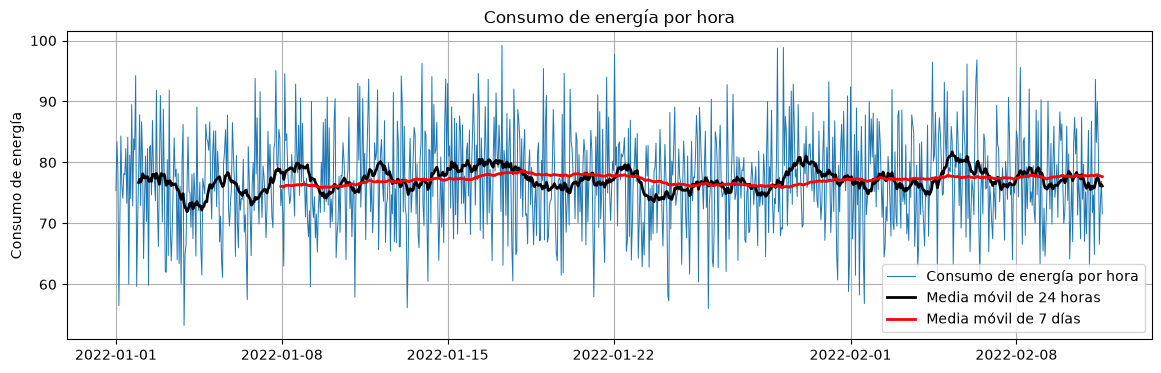

In [7]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y, lw=0.7, label="Consumo de energía por hora")
ax.plot(y.rolling(24).mean(), lw=2, color="black", label="Media móvil de 24 horas")
ax.plot(y.rolling(168).mean(), lw=2, color="red", label="Media móvil de 7 días")
ax.set_title("Consumo de energía por hora")
ax.set_ylabel("Consumo de energía")
ax.legend()
plt.show()

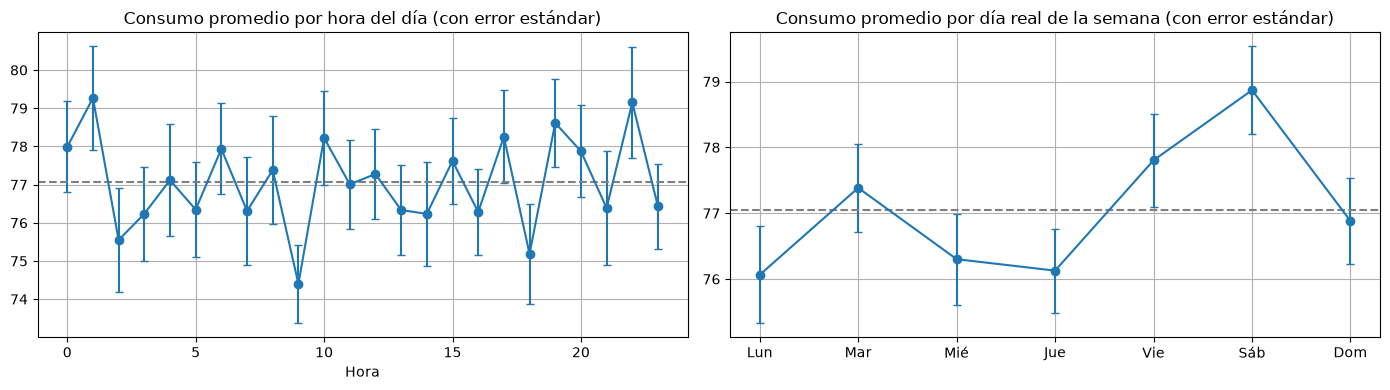

Rango de los promedios por hora: 74.4 a 79.27
Promedio por día de la semana:
Timestamp
Lun    76.06
Mar    77.38
Mié    76.30
Jue    76.13
Vie    77.80
Sáb    78.87
Dom    76.88
Name: EnergyConsumption, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_hora = y.groupby(y.index.hour)
axes[0].errorbar(por_hora.mean().index, por_hora.mean(), yerr=por_hora.std() / np.sqrt(por_hora.size()), fmt="o-", capsize=3)
axes[0].axhline(y.mean(), color="gray", ls="--")
axes[0].set_title("Consumo promedio por hora del día (con error estándar)")
axes[0].set_xlabel("Hora")

por_dia = y.groupby(y.index.dayofweek)
axes[1].errorbar(por_dia.mean().index, por_dia.mean(), yerr=por_dia.std() / np.sqrt(por_dia.size()), fmt="o-", capsize=3)
axes[1].axhline(y.mean(), color="gray", ls="--")
axes[1].set_xticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
axes[1].set_title("Consumo promedio por día real de la semana (con error estándar)")
plt.tight_layout()
plt.show()

print("Rango de los promedios por hora:", round(por_hora.mean().min(), 2), "a", round(por_hora.mean().max(), 2))
print("Promedio por día de la semana:")
print(por_dia.mean().round(2).rename(index=dict(enumerate(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]))))

Para revisar la estacionalidad de forma más formal, se aplica un ANOVA de un factor por hora del día y otro por día de la semana. La hipótesis nula es que todos los grupos tienen el mismo consumo promedio. Además del valor p se calcula eta cuadrada, que indica qué fracción de la variación total explica cada factor.

In [9]:
def anova(grupos_series, nombre):
    grupos = [g.values for _, g in grupos_series]
    f_stat, p_val = stats.f_oneway(*grupos)
    total = np.concatenate(grupos)
    ss_entre = sum(len(g) * (g.mean() - total.mean()) ** 2 for g in grupos)
    eta2 = ss_entre / ((total - total.mean()) ** 2).sum()
    print(f"ANOVA por {nombre}: F = {f_stat:.3f}, valor p = {p_val:.4f}, eta cuadrada = {eta2:.3f}")

anova(y.groupby(y.index.hour), "hora del día")
anova(y.groupby(y.index.dayofweek), "día de la semana")

ANOVA por hora del día: F = 0.939, valor p = 0.5444, eta cuadrada = 0.022
ANOVA por día de la semana: F = 2.324, valor p = 0.0311, eta cuadrada = 0.014


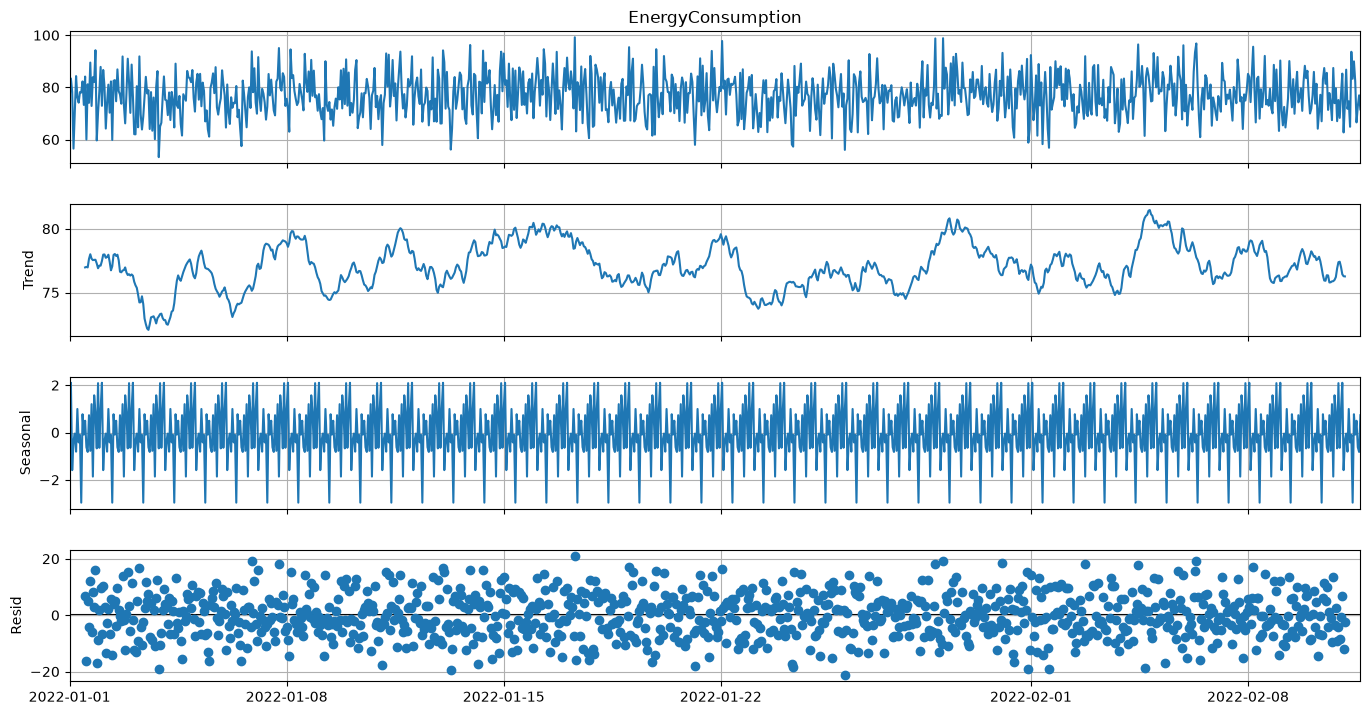

Fuerza de la estacionalidad diaria (0 = nula, 1 = muy fuerte): 0.023
Fuerza de la tendencia (0 = nula, 1 = muy fuerte): 0.054


In [10]:
descomp = seasonal_decompose(y, model="additive", period=24)
fig = descomp.plot()
fig.set_size_inches(14, 8)
plt.show()

var_resid = descomp.resid.var()
fuerza_estac = max(0, 1 - var_resid / (descomp.seasonal + descomp.resid).var())
fuerza_tend = max(0, 1 - var_resid / (descomp.trend + descomp.resid).var())
print(f"Fuerza de la estacionalidad diaria (0 = nula, 1 = muy fuerte): {fuerza_estac:.3f}")
print(f"Fuerza de la tendencia (0 = nula, 1 = muy fuerte): {fuerza_tend:.3f}")

## 3.1 Interpretación de la tendencia y la estacionalidad

La serie se mueve alrededor de un nivel constante de unas 77 unidades, con una desviación estándar de aproximadamente 8 y valores entre 53 y 99. La media móvil de 7 días es casi plana, así que no hay una tendencia de largo plazo visible en las seis semanas de datos.

El perfil por hora no muestra el patrón que esperaríamos de un edificio real, con consumo bajo en la noche y un pico en horas de trabajo. Los promedios por hora solo van de 74.4 a 79.3 y casi todas sus barras de error se cruzan con la media general. La excepción más visible son las 9:00, pero con 24 horas comparadas es normal que alguna se aleje por azar, y no hay un bloque de horas consecutivas más alto o más bajo que sugiera un ciclo. El ANOVA por hora da un valor p de 0.54, así que no podemos rechazar que todas las horas tengan el mismo consumo promedio. Por lo tanto no hay estacionalidad diaria.

Por día de la semana sí aparece una diferencia pequeña. El sábado tiene el promedio más alto, cerca de 78.9, y el lunes y el jueves los más bajos, cerca de 76.1. El ANOVA por día da un valor p de 0.031, que es significativo al 5%. Sin embargo, el efecto es muy pequeño: la eta cuadrada indica que el día de la semana explica alrededor del 1.4% de la variación, y la diferencia de unas 3 unidades entre el día más alto y el más bajo es mucho menor que la variación de una hora a otra, de unas 8 unidades. Además, como se hicieron dos pruebas, con una corrección de Bonferroni el nivel de significancia sería 0.025, y con ese criterio el resultado ya no sería significativo. Con solo seis semanas de datos hay apenas seis repeticiones de cada día, lo cual no basta para confirmar un patrón semanal estable.

La descomposición con periodo 24 confirma lo anterior. El componente estacional es pequeño comparado con el residuo, y las medidas de fuerza de la estacionalidad y de la tendencia son cercanas a cero. Es decir, casi toda la variación de la serie es ruido irregular. Esto es importante para el resto del análisis, porque sugiere que la serie ya será estacionaria y que los valores pasados darán muy poca información sobre los valores futuros.

## 4. Pruebas de estacionariedad

Se aplican dos pruebas complementarias. La prueba Dickey Fuller aumentada (ADF) tiene como hipótesis nula que la serie tiene raíz unitaria, es decir, que no es estacionaria. Un valor p menor a 0.05 rechaza esa hipótesis y apoya la estacionariedad. La prueba KPSS funciona al revés: su hipótesis nula es que la serie es estacionaria alrededor de un nivel constante, así que un valor p menor a 0.05 indica que no es estacionaria. Usar las dos da una conclusión más sólida. Cuando ADF rechaza y KPSS no rechaza, ambas pruebas coinciden en que la serie es estacionaria.

In [11]:
def prueba_adf(serie, nombre):
    stat, p, rezagos, nobs, crit, _ = adfuller(serie.dropna(), autolag="AIC")
    print(f"Prueba ADF sobre {nombre}")
    print(f"  estadístico = {stat:.3f}, valor p = {p:.4f}, rezagos usados = {rezagos}")
    print(f"  valores críticos: 1% {crit['1%']:.3f}, 5% {crit['5%']:.3f}, 10% {crit['10%']:.3f}")
    print("  conclusión:", "se rechaza la raíz unitaria, la serie es estacionaria" if p < 0.05 else "no se rechaza la raíz unitaria, la serie no es estacionaria")
    return p

def prueba_kpss(serie, nombre):
    stat, p, rezagos, crit = kpss(serie.dropna(), regression="c", nlags="auto")
    print(f"Prueba KPSS sobre {nombre}")
    print(f"  estadístico = {stat:.3f}, valor p = {p:.4f}, rezagos usados = {rezagos}")
    print(f"  valores críticos: 1% {crit['1%']:.3f}, 5% {crit['5%']:.3f}, 10% {crit['10%']:.3f}")
    print("  conclusión:", "se rechaza la estacionariedad, la serie no es estacionaria" if p < 0.05 else "no se rechaza la estacionariedad, la serie es estacionaria")
    return p

p_adf = prueba_adf(y, "EnergyConsumption")
print()
p_kpss = prueba_kpss(y, "EnergyConsumption")

Prueba ADF sobre EnergyConsumption
  estadístico = -31.577, valor p = 0.0000, rezagos usados = 0
  valores críticos: 1% -3.437, 5% -2.864, 10% -2.568
  conclusión: se rechaza la raíz unitaria, la serie es estacionaria

Prueba KPSS sobre EnergyConsumption
  estadístico = 0.190, valor p = 0.1000, rezagos usados = 5
  valores críticos: 1% 0.739, 5% 0.463, 10% 0.347
  conclusión: no se rechaza la estacionariedad, la serie es estacionaria


## 4.1 Interpretación de las pruebas de estacionariedad

El estadístico ADF es mucho menor que el valor crítico del 1% y su valor p es prácticamente cero, así que la hipótesis de raíz unitaria se rechaza con claridad. El estadístico KPSS es menor incluso que el valor crítico del 10%. Statsmodels reporta un valor p de 0.10 porque ese es el límite superior de su tabla de valores, lo que significa que el valor p real es mayor a 0.10. Por lo tanto KPSS no rechaza la estacionariedad.

Las dos pruebas coinciden: la serie es estacionaria en su nivel original. Por esa razón no se aplica diferenciación simple, y el orden de integración es d = 0. Tampoco se aplica diferenciación estacional, porque la sección anterior no mostró estacionalidad diaria, así que D = 0.

Para mostrar qué pasaría si de todos modos se diferenciara, abajo también se prueba la primera diferencia y se revisa su ACF. Esto es una verificación de sobrediferenciación, no una transformación que se use en los modelos finales.

Prueba ADF sobre la primera diferencia
  estadístico = -12.804, valor p = 0.0000, rezagos usados = 20
  valores críticos: 1% -3.437, 5% -2.864, 10% -2.568
  conclusión: se rechaza la raíz unitaria, la serie es estacionaria


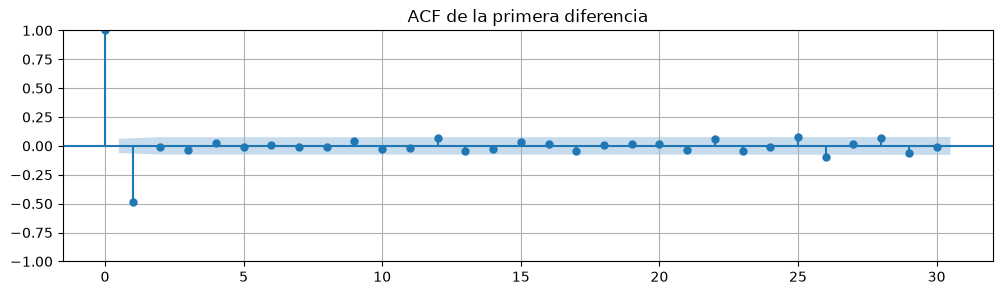

Autocorrelación en el rezago 1 de la serie diferenciada: -0.485
Varianza original: 66.33   Varianza diferenciada: 132.79


In [12]:
y_dif = y.diff().dropna()
prueba_adf(y_dif, "la primera diferencia")
fig, ax = plt.subplots(figsize=(12, 3))
plot_acf(y_dif, lags=30, ax=ax, title="ACF de la primera diferencia")
plt.show()
print(f"Autocorrelación en el rezago 1 de la serie diferenciada: {y_dif.autocorr(1):.3f}")
print(f"Varianza original: {y.var():.2f}   Varianza diferenciada: {y_dif.var():.2f}")

La serie diferenciada tiene una autocorrelación negativa fuerte, de aproximadamente menos 0.5, en el rezago 1, y su varianza se duplica, de 66 a 133. Estas son las señales clásicas de sobrediferenciación: diferenciar una serie que ya era estacionaria agrega una estructura MA artificial y más ruido. Esto confirma que d = 0 es la elección correcta.

## 5. ACF y PACF para elegir los parámetros

La ACF ayuda a elegir el orden MA, q, y la PACF ayuda a elegir el orden AR, p. Se muestran rezagos de hasta 72 horas para que cualquier patrón diario en los rezagos 24, 48 y 72 también sea visible. El área sombreada es la banda de confianza del 95%. Los picos fuera de ella son significativos.

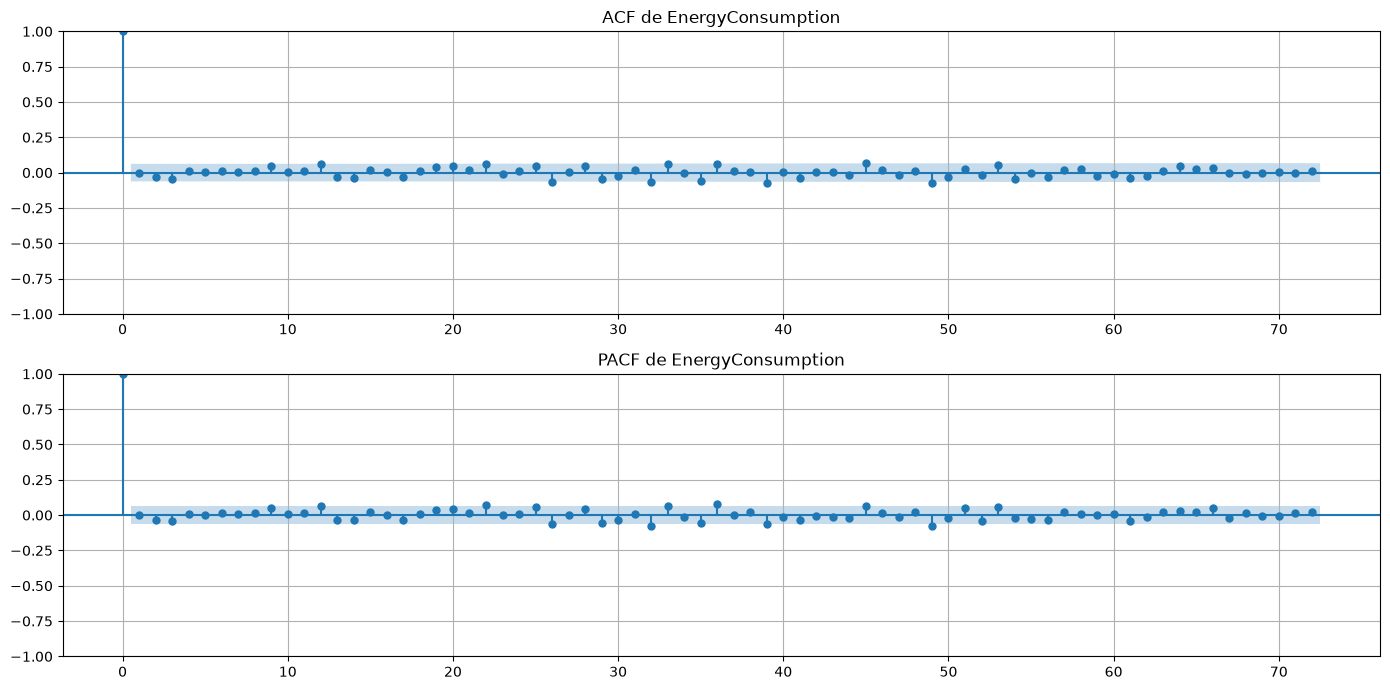

Banda del 95%: +/- 0.062
ACF en los rezagos 1, 2, 3, 24, 48, 72: [-0.    -0.031 -0.043  0.008  0.009  0.013]
PACF en los rezagos 1, 2, 3, 24, 48, 72: [-0.    -0.031 -0.043  0.008  0.024  0.022]
Rezagos de la ACF fuera de la banda: [22, 26, 32, 35, 39, 45, 49]
Rezagos de la PACF fuera de la banda: [12, 22, 26, 32, 36, 39, 45, 49]
Valor absoluto más grande fuera del rezago 0, ACF: 0.072  PACF: 0.079


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(y, lags=72, ax=axes[0], title="ACF de EnergyConsumption")
plot_pacf(y, lags=72, ax=axes[1], method="ywm", title="PACF de EnergyConsumption")
plt.tight_layout()
plt.show()

banda = 1.96 / np.sqrt(len(y))
acf_v = acf(y, nlags=72)
pacf_v = pacf(y, nlags=72, method="ywm")
print(f"Banda del 95%: +/- {banda:.3f}")
print("ACF en los rezagos 1, 2, 3, 24, 48, 72:", np.round(acf_v[[1, 2, 3, 24, 48, 72]], 3))
print("PACF en los rezagos 1, 2, 3, 24, 48, 72:", np.round(pacf_v[[1, 2, 3, 24, 48, 72]], 3))
print("Rezagos de la ACF fuera de la banda:", [r for r in range(1, 73) if abs(acf_v[r]) > banda])
print("Rezagos de la PACF fuera de la banda:", [r for r in range(1, 73) if abs(pacf_v[r]) > banda])
print("Valor absoluto más grande fuera del rezago 0, ACF:", round(np.abs(acf_v[1:]).max(), 3), " PACF:", round(np.abs(pacf_v[1:]).max(), 3))

## 5.1 Interpretación de la ACF y la PACF

Casi todas las autocorrelaciones y autocorrelaciones parciales están dentro de la banda de confianza. Los primeros rezagos, que son los que más importan para elegir p y q, son prácticamente cero. Por ejemplo, la autocorrelación en el rezago 1 es 0.000. Algunos rezagos sueltos, como el 12, 22, 26 o 32, cruzan la banda, pero apenas: ninguno pasa de 0.08 en valor absoluto. Están dispersos y no forman un patrón que decaiga o se repita. Con una banda del 95% y 72 rezagos se esperan entre tres y cuatro cruces solo por azar en cada gráfica, y los pocos cruces extra son tan pequeños que no tienen relevancia práctica. No hay picos en los rezagos estacionales 24, 48 o 72. Este patrón es la firma del ruido blanco.

Con base en esto, la ACF y la PACF apuntan a un ARIMA(0,0,0), que es una media constante más ruido aleatorio. Como la tarea pide comparar al menos dos modelos, también se ajustan dos candidatos más generales para comprobar si un poco de estructura autorregresiva o de media móvil ayuda. Los modelos candidatos son ARIMA(0,0,0), ARIMA(1,0,1) y ARIMA(2,0,2), todos con constante. También se ajusta un SARIMA(1,0,1)(1,0,1,24) para probar formalmente si un componente estacional diario aporta algo, aunque el análisis anterior sugiere que no.

## 6. División en entrenamiento y prueba

Las últimas 30 horas se separan como conjunto de prueba. Cada modelo se entrena solo con las primeras 970 horas y después pronostica esas 30 horas, así que el RMSE mide la precisión en datos que el modelo nunca vio.

In [14]:
h = 30
train, test = y.iloc[:-h], y.iloc[-h:]
print("Entrenamiento:", train.index.min(), "a", train.index.max(), "|", len(train), "horas")
print("Prueba:       ", test.index.min(), "a", test.index.max(), "|", len(test), "horas")

Entrenamiento: 2022-01-01 00:00:00 a 2022-02-10 09:00:00 | 970 horas
Prueba:        2022-02-10 10:00:00 a 2022-02-11 15:00:00 | 30 horas


## 7. Ajuste de los modelos

In [15]:
specs = {
    "ARIMA(0,0,0)": dict(order=(0, 0, 0)),
    "ARIMA(1,0,1)": dict(order=(1, 0, 1)),
    "ARIMA(2,0,2)": dict(order=(2, 0, 2)),
}
fits, pronosticos = {}, {}
for nombre, kw in specs.items():
    fits[nombre] = ARIMA(train, trend="c", **kw).fit()
    pronosticos[nombre] = fits[nombre].get_forecast(h)

fits["SARIMA(1,0,1)(1,0,1,24)"] = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24), trend="c").fit(disp=False, maxiter=200)
pronosticos["SARIMA(1,0,1)(1,0,1,24)"] = fits["SARIMA(1,0,1)(1,0,1,24)"].get_forecast(h)

for nombre, fit in fits.items():
    print(f"{nombre}: convergió = {fit.mle_retvals.get('converged', True)}")

ARIMA(0,0,0): convergió = True
ARIMA(1,0,1): convergió = True
ARIMA(2,0,2): convergió = True
SARIMA(1,0,1)(1,0,1,24): convergió = True


In [16]:
print(fits["ARIMA(1,0,1)"].summary())

                               SARIMAX Results                                
Dep. Variable:      EnergyConsumption   No. Observations:                  970
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -3410.893
Date:                Tue, 03 Nov 2026   AIC                           6829.787
Time:                        08:53:55   BIC                           6849.296
Sample:                    01-01-2022   HQIC                          6837.212
                         - 02-10-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         77.0519      0.265    291.290      0.000      76.533      77.570
ar.L1         -0.2806      4.319     -0.065      0.948      -8.745       8.184
ma.L1          0.2872      4.311      0.067      0.9

In [17]:
print(fits["SARIMA(1,0,1)(1,0,1,24)"].summary())

                                     SARIMAX Results                                      
Dep. Variable:                  EnergyConsumption   No. Observations:                  970
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 24)   Log Likelihood               -3410.860
Date:                            Tue, 03 Nov 2026   AIC                           6833.720
Time:                                    08:53:55   BIC                           6862.984
Sample:                                01-01-2022   HQIC                          6844.859
                                     - 02-10-2022                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     82.3272   1190.868      0.069      0.945   -2251.732    2416.386
ar.L1         -0.6144     21.917   

In [18]:
print("Coeficientes y valores p del ARIMA(2,0,2):")
print(pd.DataFrame({"coeficiente": fits["ARIMA(2,0,2)"].params, "valor p": fits["ARIMA(2,0,2)"].pvalues}).round(3))

Coeficientes y valores p del ARIMA(2,0,2):
        coeficiente  valor p
const        77.054    0.000
ar.L1         0.631    0.257
ar.L2        -0.476    0.387
ma.L1        -0.628    0.270
ma.L2         0.436    0.441
sigma2       66.196    0.000


Todos los modelos convergieron. En el resumen del ARIMA(1,0,1), el coeficiente AR es aproximadamente menos 0.28 y el MA aproximadamente más 0.29. Al ser casi iguales y de signo contrario, se anulan entre sí, y el modelo termina siendo equivalente a una media constante. Esto se conoce como redundancia de parámetros, y por eso sus errores estándar son enormes, de más de 4, y sus valores p son cercanos a 0.95. Lo mismo pasa en el SARIMA, tanto en la parte no estacional como en la estacional, y en el ARIMA(2,0,2), donde ningún coeficiente AR o MA es significativo al 5%. Solo la constante es claramente significativa en todos. Los parámetros extra están describiendo ruido y no una estructura real, lo cual coincide con la ACF y la PACF.

## 8. Comparación de modelos con AIC, BIC y RMSE

AIC y BIC miden el ajuste dentro de la muestra y penalizan el número de parámetros. BIC penaliza más fuerte los parámetros extra. En ambos, un valor menor es mejor. El RMSE y el MAE se calculan en las 30 horas de prueba y miden la precisión fuera de la muestra, en las mismas unidades que los datos. Como referencia se incluye un pronóstico ingenuo que siempre predice la media del entrenamiento.

In [19]:
filas = []
for nombre, fit in fits.items():
    pred = pronosticos[nombre].predicted_mean
    filas.append({
        "Modelo": nombre,
        "Parámetros": len(fit.params),
        "AIC": fit.aic,
        "BIC": fit.bic,
        "RMSE prueba": np.sqrt(mean_squared_error(test, pred)),
        "MAE prueba": mean_absolute_error(test, pred),
    })
ingenuo = np.repeat(train.mean(), h)
filas.append({"Modelo": "Media del entrenamiento (ingenuo)", "Parámetros": 1, "AIC": np.nan, "BIC": np.nan,
              "RMSE prueba": np.sqrt(mean_squared_error(test, ingenuo)), "MAE prueba": mean_absolute_error(test, ingenuo)})
comparacion = pd.DataFrame(filas).set_index("Modelo").round(3)
comparacion

,Parámetros,AIC,BIC,RMSE prueba,MAE prueba
Modelo,,,,,
"ARIMA(0,0,0)",2,6825.833,6835.587,7.960,6.746
"ARIMA(1,0,1)",4,6829.787,6849.296,7.961,6.747
"ARIMA(2,0,2)",6,6831.586,6860.850,7.948,6.733
"SARIMA(1,0,1)(1,0,1,24)",6,6833.720,6862.984,7.962,6.756
Media del entrenamiento (ingenuo),1,NaN,NaN,7.960,6.746


## 8.1 Interpretación de la comparación

El ARIMA(0,0,0) tiene el AIC y el BIC más bajos. Cada par extra de términos AR y MA empeora ligeramente el AIC y el BIC, porque la pequeña mejora en la verosimilitud no compensa la penalización por los parámetros agregados. El SARIMA tiene el peor AIC y BIC del grupo, porque agrega cuatro parámetros más sin explicar variación adicional.

En el conjunto de prueba, el RMSE de todos los modelos ronda 8, que es casi igual a la desviación estándar de la serie. Todos los modelos, incluyendo la media ingenua, quedan a unas centésimas uno de otro. El ARIMA(2,0,2) tiene el RMSE más bajo, pero solo es 0.01 unidades mejor que el ARIMA(0,0,0), menos del 0.2% del error, y con solo 30 puntos de prueba esa diferencia no es significativa. Cuando la complejidad extra no da una mejora real en precisión, el principio de parsimonia indica que hay que elegir el modelo más simple, así que el ARIMA(0,0,0) es el modelo preferido.

## 9. Diagnóstico de residuos

Un buen modelo debe dejar residuos que se comporten como ruido blanco. Se revisan tres propiedades en cada modelo. La autocorrelación se revisa con la prueba de Ljung Box en los rezagos 10 y 24, descontando los grados de libertad que usa cada modelo. Un valor p mayor a 0.05 significa que no queda autocorrelación. La normalidad se revisa con la prueba de Jarque Bera, donde un valor p mayor a 0.05 indica que los residuos son consistentes con una distribución normal. La varianza constante se revisa con la prueba ARCH de Engle, donde un valor p mayor a 0.05 indica que no hay evidencia de que la varianza cambie en el tiempo.

In [20]:
n_arma = {"ARIMA(0,0,0)": 0, "ARIMA(1,0,1)": 2, "ARIMA(2,0,2)": 4, "SARIMA(1,0,1)(1,0,1,24)": 4}
filas_diag = []
for nombre, fit in fits.items():
    r = fit.resid.iloc[30:] if "SARIMA" in nombre else fit.resid.iloc[1:]  # se omiten los primeros valores, donde el modelo aún se está inicializando
    lb = acorr_ljungbox(r, lags=[10, 24], model_df=n_arma[nombre], return_df=True)
    jb_stat, jb_p = stats.jarque_bera(r)
    arch_p = het_arch(r, nlags=12)[1]
    filas_diag.append({
        "Modelo": nombre,
        "Ljung-Box p (rezago 10)": lb.loc[10, "lb_pvalue"],
        "Ljung-Box p (rezago 24)": lb.loc[24, "lb_pvalue"],
        "Jarque-Bera p": jb_p,
        "ARCH p (12 rezagos)": arch_p,
        "Asimetría": stats.skew(r),
        "Curtosis en exceso": stats.kurtosis(r),
    })
diagnostico = pd.DataFrame(filas_diag).set_index("Modelo").round(3)
diagnostico

,Ljung-Box p (rezago 10),Ljung-Box p (rezago 24),Jarque-Bera p,ARCH p (12 rezagos),Asimetría,Curtosis en exceso
Modelo,,,,,,
"ARIMA(0,0,0)",0.819,0.535,0.174,0.756,0.023,-0.291
"ARIMA(1,0,1)",0.661,0.428,0.173,0.763,0.026,-0.290
"ARIMA(2,0,2)",0.641,0.362,0.177,0.770,0.029,-0.287
"SARIMA(1,0,1)(1,0,1,24)",0.398,0.388,0.140,0.801,0.044,-0.304


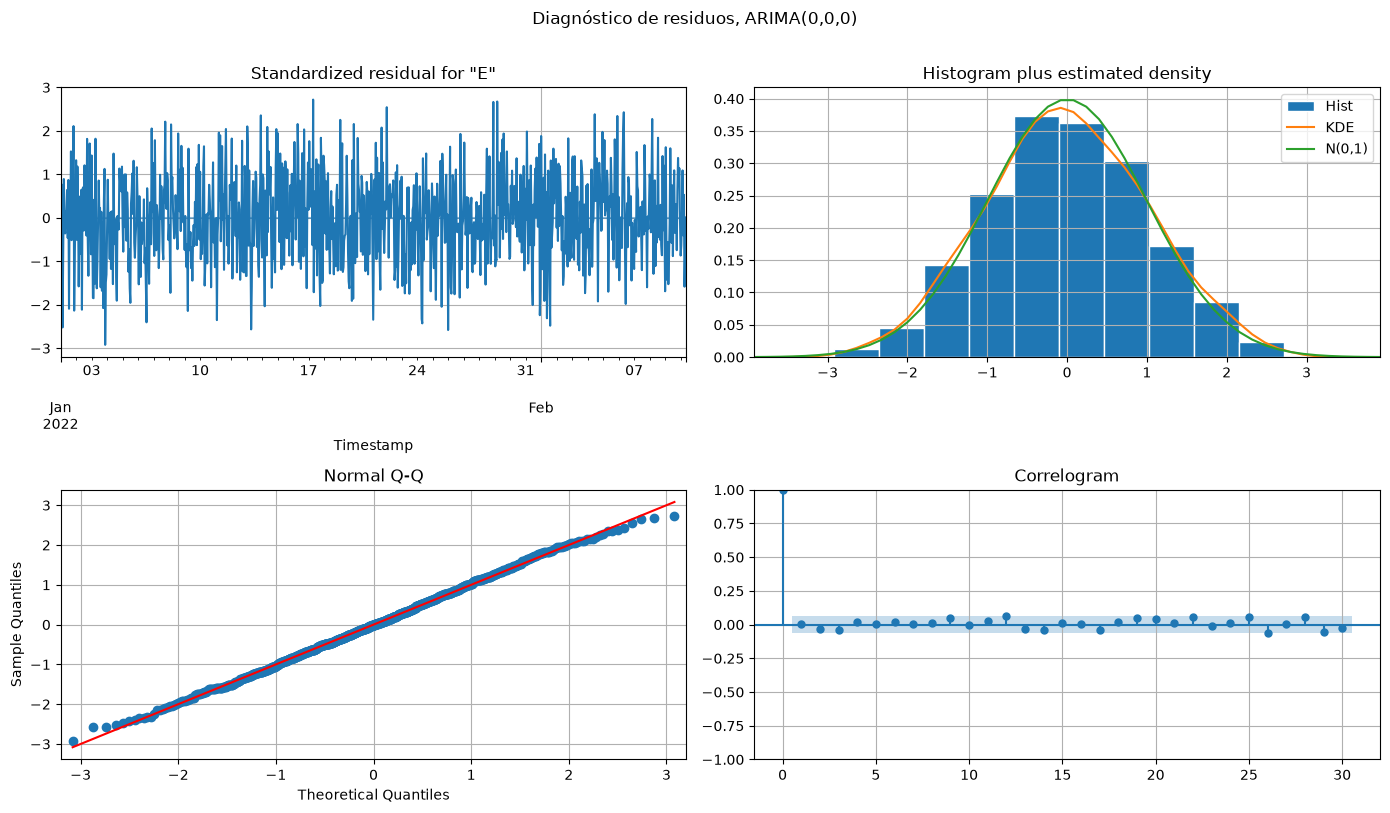

In [21]:
fig = fits["ARIMA(0,0,0)"].plot_diagnostics(figsize=(14, 8), lags=30)
fig.suptitle("Diagnóstico de residuos, ARIMA(0,0,0)", y=1.01)
plt.tight_layout()
plt.show()

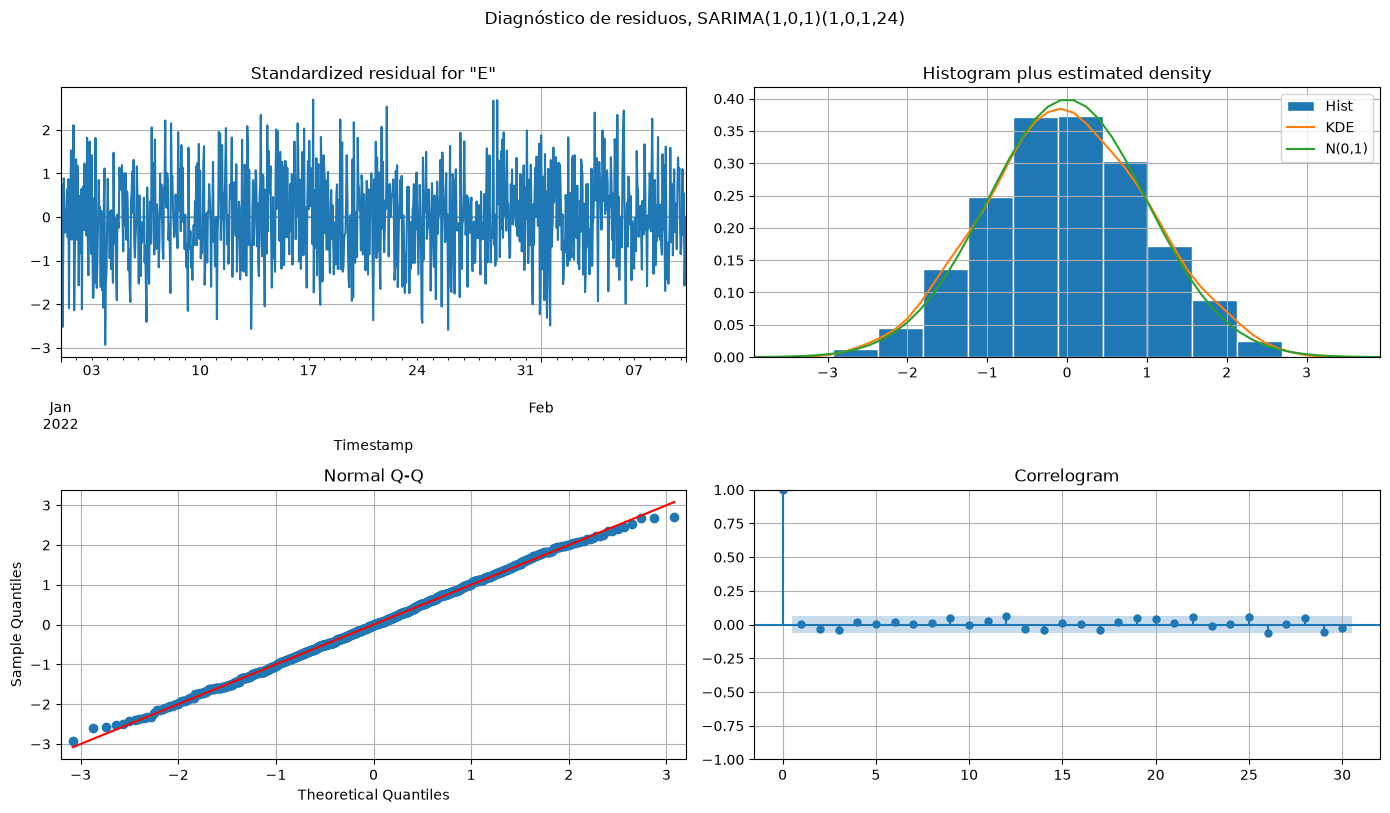

In [22]:
fig = fits["SARIMA(1,0,1)(1,0,1,24)"].plot_diagnostics(figsize=(14, 8), lags=30)
fig.suptitle("Diagnóstico de residuos, SARIMA(1,0,1)(1,0,1,24)", y=1.01)
plt.tight_layout()
plt.show()

## 9.1 Interpretación del diagnóstico

En todos los modelos, los valores p de Ljung Box son mayores a 0.05 en los rezagos 10 y 24, así que no queda autocorrelación en los residuos. El correlograma de las gráficas de diagnóstico muestra todos los rezagos dentro o prácticamente dentro de la banda. Los valores p de Jarque Bera también son mayores a 0.05. La asimetría es casi cero y la curtosis en exceso es ligeramente negativa, alrededor de menos 0.3, lo que indica colas un poco más ligeras que las de una normal, pero no lo suficiente para rechazar la normalidad. El histograma y la gráfica Q-Q siguen de cerca la curva normal. Por último, los valores p de la prueba ARCH son mayores a 0.05 y los residuos estandarizados tienen una dispersión estable en el tiempo, así que también se cumple el supuesto de varianza constante.

Los supuestos se cumplen en todos los modelos, pero aquí eso tiene un significado específico. Incluso el ARIMA(0,0,0), que solo resta una constante, ya produce residuos de ruido blanco. Esto muestra que la serie original ya es casi ruido blanco puro alrededor de su media, y que los términos AR, MA y estacionales de los demás modelos no tienen nada que capturar.

## 10. Pronóstico en el conjunto de prueba: valores reales contra predichos

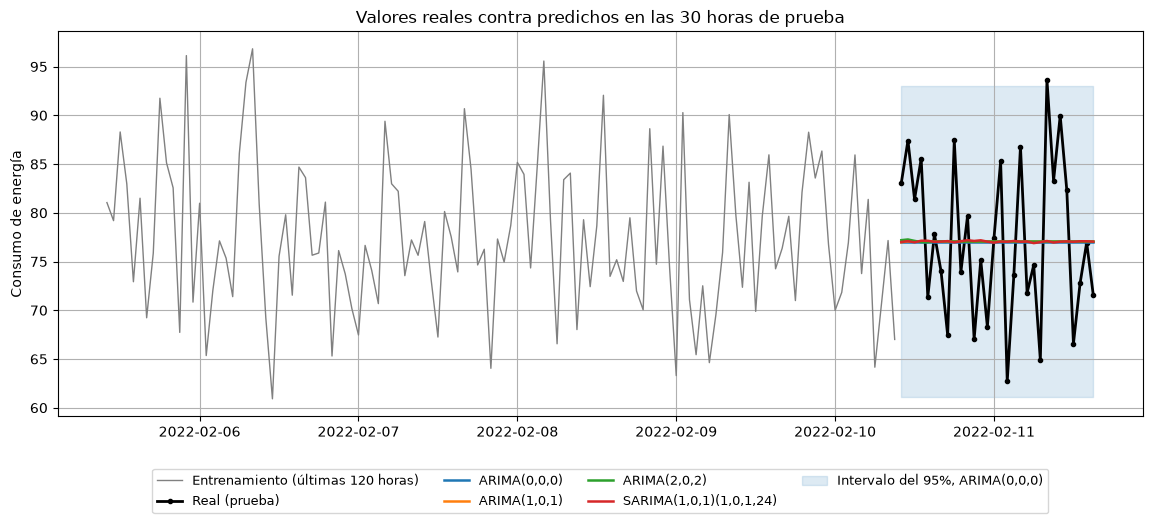

Porcentaje de puntos de prueba dentro del intervalo del 95% del ARIMA(0,0,0): 97%


In [23]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.iloc[-120:], color="gray", lw=1, label="Entrenamiento (últimas 120 horas)")
ax.plot(test, color="black", lw=2, marker="o", ms=3, label="Real (prueba)")
colores = {"ARIMA(0,0,0)": "tab:blue", "ARIMA(1,0,1)": "tab:orange", "ARIMA(2,0,2)": "tab:green", "SARIMA(1,0,1)(1,0,1,24)": "tab:red"}
for nombre, fc in pronosticos.items():
    ax.plot(fc.predicted_mean, color=colores[nombre], lw=1.8, label=nombre)
ic = pronosticos["ARIMA(0,0,0)"].conf_int(alpha=0.05)
ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color="tab:blue", alpha=0.15, label="Intervalo del 95%, ARIMA(0,0,0)")
ax.set_title("Valores reales contra predichos en las 30 horas de prueba")
ax.set_ylabel("Consumo de energía")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)
plt.show()

dentro = ((test >= ic.iloc[:, 0]) & (test <= ic.iloc[:, 1])).mean()
print(f"Porcentaje de puntos de prueba dentro del intervalo del 95% del ARIMA(0,0,0): {dentro:.0%}")

## 10.1 Interpretación del desempeño del pronóstico

Todos los pronósticos son prácticamente líneas planas cerca de la media de 77. El ARIMA(1,0,1) se queda casi pegado a la media desde la primera hora, porque sus coeficientes AR y MA se anulan. El ARIMA(2,0,2) y el SARIMA agregan pequeñas oscilaciones, de unas décimas de unidad, que no siguen a los valores reales.

El consumo real sube y baja alrededor del pronóstico sin ningún patrón que alguno de los modelos pueda anticipar. Por eso el RMSE se mantiene cerca de la desviación estándar de los datos. Aun así, el pronóstico es útil en un sentido: el intervalo de predicción del 95%, de aproximadamente más o menos 16 unidades, contiene 29 de los 30 puntos de prueba. Es decir, el modelo describe correctamente el nivel típico y el rango esperado del consumo, aunque no pueda predecir el valor exacto de cada hora.

## 11. Pronóstico final de las siguientes 30 horas

El modelo elegido, ARIMA(0,0,0) con constante, se vuelve a ajustar con las 1,000 horas completas y se usa para pronosticar las 30 horas posteriores al final del dataset, del 11 de febrero de 2022 a las 16:00 al 12 de febrero de 2022 a las 21:00.

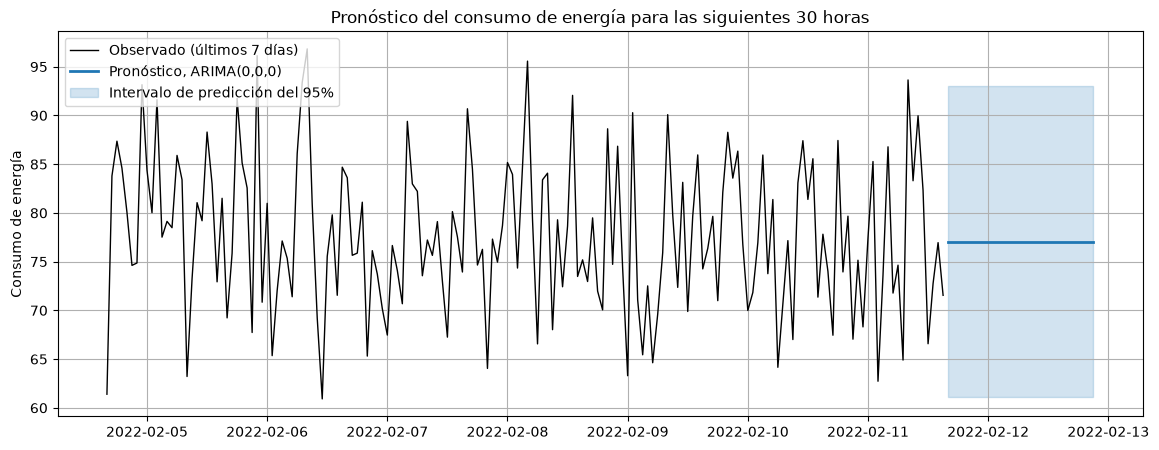

,Pronóstico,Límite inferior 95%,Límite superior 95%
2022-02-11 16:00:00,77.06,61.1,93.01
2022-02-11 17:00:00,77.06,61.1,93.01
2022-02-11 18:00:00,77.06,61.1,93.01
2022-02-11 19:00:00,77.06,61.1,93.01
2022-02-11 20:00:00,77.06,61.1,93.01
2022-02-11 21:00:00,77.06,61.1,93.01
2022-02-11 22:00:00,77.06,61.1,93.01
2022-02-11 23:00:00,77.06,61.1,93.01
2022-02-12 00:00:00,77.06,61.1,93.01
2022-02-12 01:00:00,77.06,61.1,93.01


In [24]:
fit_final = ARIMA(y, order=(0, 0, 0), trend="c").fit()
fc_final = fit_final.get_forecast(h)
ic_final = fc_final.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y.iloc[-168:], color="black", lw=1, label="Observado (últimos 7 días)")
ax.plot(fc_final.predicted_mean, color="tab:blue", lw=2, label="Pronóstico, ARIMA(0,0,0)")
ax.fill_between(ic_final.index, ic_final.iloc[:, 0], ic_final.iloc[:, 1], color="tab:blue", alpha=0.2, label="Intervalo de predicción del 95%")
ax.set_title("Pronóstico del consumo de energía para las siguientes 30 horas")
ax.set_ylabel("Consumo de energía")
ax.legend(loc="upper left")
plt.show()

tabla_pronostico = pd.DataFrame({
    "Pronóstico": fc_final.predicted_mean,
    "Límite inferior 95%": ic_final.iloc[:, 0],
    "Límite superior 95%": ic_final.iloc[:, 1],
}).round(2)
tabla_pronostico

## 12. Conclusiones

La serie de consumo de energía tiene 1,000 observaciones por hora completas, sin valores ni horas faltantes. El único problema de calidad de datos encontrado fue la columna DayOfWeek, que no coincide con el día real de la fecha y por eso no se usó.

El análisis visual, el ANOVA por hora del día y la descomposición estacional muestran que la serie no tiene tendencia ni estacionalidad diaria. Por día de la semana aparece una diferencia estadísticamente significativa pero muy pequeña, de unas 3 unidades, que explica cerca del 1.4% de la variación y que no es suficientemente sólida con solo seis semanas de datos. El consumo fluctúa al azar alrededor de una media estable de unas 77 unidades.

Las pruebas ADF y KPSS coinciden en que la serie es estacionaria en su nivel original, así que no fue necesario diferenciar y d = 0. Diferenciar de todos modos causaría sobrediferenciación, como lo muestran la autocorrelación de menos 0.5 en el rezago 1 y la varianza duplicada de la serie diferenciada.

La ACF y la PACF no muestran rezagos significativos de corto plazo ni estacionales, lo cual apunta a un proceso de ruido blanco y a un ARIMA(0,0,0). Entre los modelos comparados, el ARIMA(0,0,0) tiene el AIC y el BIC más bajos. Todos los modelos, incluyendo el SARIMA y el pronóstico ingenuo de la media, tienen prácticamente el mismo RMSE de prueba, de aproximadamente 8. Los residuos de todos los modelos pasan las pruebas de no autocorrelación, normalidad y varianza constante.

El mejor modelo es el ARIMA(0,0,0) con constante. Se elige porque tiene el mejor AIC y BIC, iguala la precisión de los modelos más complejos y es el más simple. Agregar términos AR, MA o estacionales solo ajusta ruido, produce coeficientes no significativos que incluso se anulan entre sí, y empeora los criterios de información. El SARIMA se implementó para probar formalmente la estacionalidad diaria, y el resultado es que un componente estacional no se justifica con estos datos.

Un punto crítico es que este dataset parece ser sintético. Un edificio real normalmente mostraría un ciclo diario claro, con menor consumo en la noche y mayor consumo durante el día, y ese ciclo sería lo principal que capturaría un modelo SARIMA. Aquí los valores por hora se comportan como sorteos aleatorios independientes, así que el mejor pronóstico posible con modelos tipo ARIMA es la media histórica con una banda de incertidumbre. Si el objetivo fuera predecir mejor cada hora, el siguiente paso sería usar las variables explicativas del dataset, como temperatura, ocupación y uso de aire acondicionado e iluminación, como regresores exógenos en un modelo SARIMAX o en un modelo de regresión, porque la información sobre el consumo está en esas variables y no en el pasado de la serie.